In [2]:
# 1. Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:

# 2. Load dataset
df = pd.read_csv('customer_shopping_data.csv')

# 3. Explore dataset
print("First 5 Rows:")
print(df.head())

First 5 Rows:
  invoice_no customer_id  gender  age  category  quantity    price  \
0    I138884     C241288  Female   28  Clothing         5  1500.40   
1    I317333     C111565    Male   21     Shoes         3  1800.51   
2    I127801     C266599    Male   20  Clothing         1   300.08   
3    I173702     C988172  Female   66     Shoes         5  3000.85   
4    I337046     C189076  Female   53     Books         4    60.60   

  payment_method invoice_date   shopping_mall  
0    Credit Card   05-08-2022          Kanyon  
1     Debit Card   12-12-2021  Forum Istanbul  
2           Cash   09-11-2021       Metrocity  
3    Credit Card   16-05-2021    Metropol AVM  
4           Cash   24-10-2021          Kanyon  


In [5]:
print("\nDataset Information:")
df.info()



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1998 entries, 0 to 1997
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   invoice_no      1998 non-null   object 
 1   customer_id     1998 non-null   object 
 2   gender          1998 non-null   object 
 3   age             1998 non-null   int64  
 4   category        1998 non-null   object 
 5   quantity        1998 non-null   int64  
 6   price           1998 non-null   float64
 7   payment_method  1998 non-null   object 
 8   invoice_date    1998 non-null   object 
 9   shopping_mall   1998 non-null   object 
dtypes: float64(1), int64(2), object(7)
memory usage: 156.2+ KB


In [6]:
print("\nDescriptive Statistics:")
print(df.describe())


Descriptive Statistics:
               age     quantity        price
count  1998.000000  1998.000000  1998.000000
mean     43.480981     3.026026   686.422763
std      14.904012     1.434716   969.660959
min      18.000000     1.000000     5.230000
25%      30.000000     2.000000    40.660000
50%      43.000000     3.000000   203.300000
75%      56.000000     4.000000  1200.320000
max      69.000000     5.000000  5250.000000


In [7]:
# 4. Identify relevant variables
# Region = shopping_mall
# Sales Amount = price
# Product Category = category

# 5. Calculate total sales by region
regional_sales = df.groupby('shopping_mall')['price'].sum().reset_index()

regional_sales.rename(columns={
    'shopping_mall': 'Region',
    'price': 'Total_Sales'
}, inplace=True)

print("\nTotal Sales by Region:")
print(regional_sales)


Total Sales by Region:
              Region  Total_Sales
0        Cevahir AVM     73993.17
1  Emaar Square Mall     80806.02
2     Forum Istanbul     57328.36
3       Istinye Park    116370.64
4             Kanyon    283234.43
5   Mall of Istanbul    283013.64
6          Metrocity    190861.53
7       Metropol AVM    132426.74
8     Viaport Outlet     71712.75
9       Zorlu Center     81725.40


In [8]:
# 6. Identify top 3 performing regions
regional_sales_sorted = regional_sales.sort_values(
    by='Total_Sales', ascending=False
)

print("\nTop 3 Performing Regions:")
print(regional_sales_sorted.head(3))



Top 3 Performing Regions:
             Region  Total_Sales
4            Kanyon    283234.43
5  Mall of Istanbul    283013.64
6         Metrocity    190861.53


In [9]:
# 7. Group sales by region and category
region_category_sales = df.groupby(
    ['shopping_mall', 'category']
)['price'].sum().reset_index()

region_category_sales.rename(columns={
    'shopping_mall': 'Region',
    'category': 'Product_Category',
    'price': 'Total_Sales'
}, inplace=True)

print("\nSales by Region and Category:")
print(region_category_sales.head(10))

# Export aggregated data
region_category_sales.to_csv(
    'region_category_sales.csv', index=False
)





Sales by Region and Category:
              Region Product_Category  Total_Sales
0        Cevahir AVM            Books        75.75
1        Cevahir AVM         Clothing     29407.84
2        Cevahir AVM        Cosmetics      2398.94
3        Cevahir AVM  Food & Beverage       235.35
4        Cevahir AVM            Shoes      7202.04
5        Cevahir AVM         Souvenir       105.57
6        Cevahir AVM       Technology     33600.00
7        Cevahir AVM             Toys       967.68
8  Emaar Square Mall            Books       196.95
9  Emaar Square Mall         Clothing     34809.28


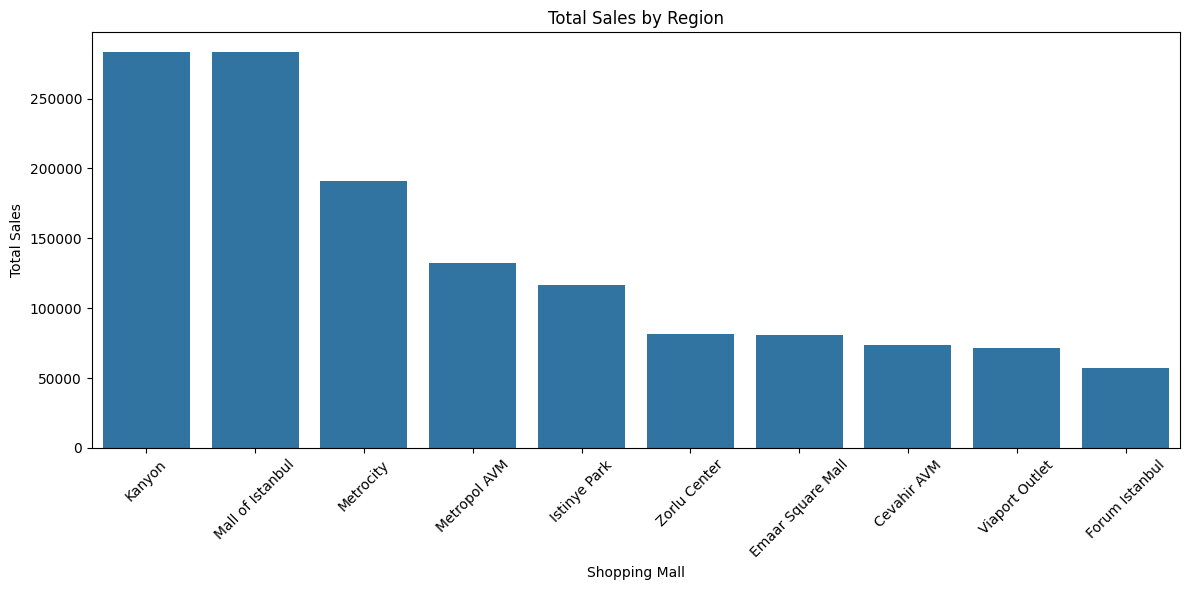

In [10]:
# 8. Create bar plot: Sales by region
plt.figure(figsize=(12, 6))
sns.barplot(data=regional_sales_sorted,
            x='Region', y='Total_Sales')

plt.title('Total Sales by Region')
plt.xlabel('Shopping Mall')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

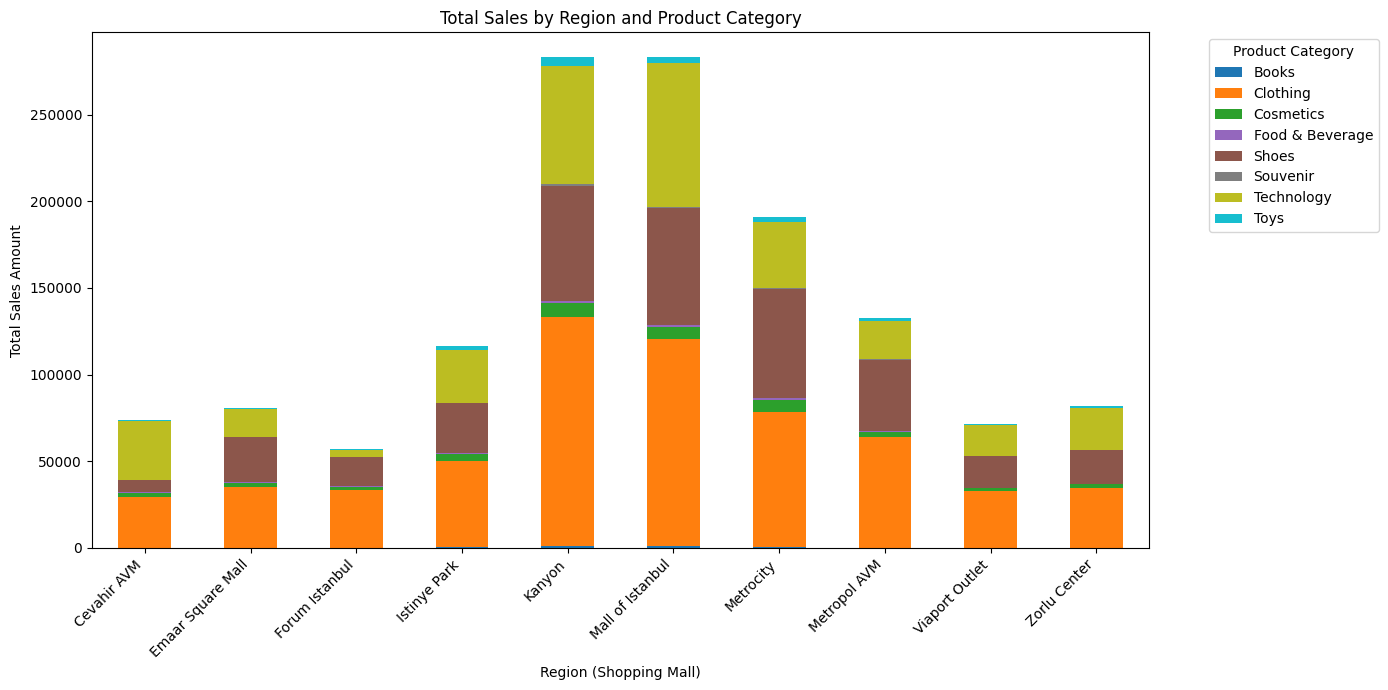


Aggregated data and chart saved successfully!


In [11]:
# 9. Create stacked bar plot
pivot_df = region_category_sales.pivot(
    index='Region',
    columns='Product_Category',
    values='Total_Sales'
).fillna(0)

pivot_df.plot(
    kind='bar',
    stacked=True,
    figsize=(14, 7),
    cmap='tab10'
)

plt.title('Total Sales by Region and Product Category')
plt.xlabel('Region (Shopping Mall)')
plt.ylabel('Total Sales Amount')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Product Category',
           bbox_to_anchor=(1.05, 1),
           loc='upper left')
plt.tight_layout()
plt.savefig('region_category_stacked_barchart.png')
plt.show()

print("\nAggregated data and chart saved successfully!")

In [ ]:

# 1. Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Load dataset
df = pd.read_csv('/content/customer_shopping_data.csv')

# 3. Explore dataset
print("First 5 Rows:")
print(df.head())

print("\nDataset Information:")
df.info()

print("\nDescriptive Statistics:")
print(df.describe())

# 4. Identify relevant variables
# Region = shopping_mall
# Sales Amount = price
# Product Category = category

# 5. Calculate total sales by region
regional_sales = df.groupby('shopping_mall')['price'].sum().reset_index()

regional_sales.rename(columns={
    'shopping_mall': 'Region',
    'price': 'Total_Sales'
}, inplace=True)

print("\nTotal Sales by Region:")
print(regional_sales)

# 6. Identify top 3 performing regions
regional_sales_sorted = regional_sales.sort_values(
    by='Total_Sales', ascending=False
)

print("\nTop 3 Performing Regions:")
print(regional_sales_sorted.head(3))

# 7. Group sales by region and category
region_category_sales = df.groupby(
    ['shopping_mall', 'category']
)['price'].sum().reset_index()

region_category_sales.rename(columns={
    'shopping_mall': 'Region',
    'category': 'Product_Category',
    'price': 'Total_Sales'
}, inplace=True)

print("\nSales by Region and Category:")
print(region_category_sales.head(10))

# Export aggregated data
region_category_sales.to_csv(
    'region_category_sales.csv', index=False
)

# 8. Create bar plot: Sales by region
plt.figure(figsize=(12, 6))
sns.barplot(data=regional_sales_sorted,
            x='Region', y='Total_Sales')

plt.title('Total Sales by Region')
plt.xlabel('Shopping Mall')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 9. Create stacked bar plot
pivot_df = region_category_sales.pivot(
    index='Region',
    columns='Product_Category',
    values='Total_Sales'
).fillna(0)

pivot_df.plot(
    kind='bar',
    stacked=True,
    figsize=(14, 7),
    cmap='tab10'
)

plt.title('Total Sales by Region and Product Category')
plt.xlabel('Region (Shopping Mall)')
plt.ylabel('Total Sales Amount')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Product Category',
           bbox_to_anchor=(1.05, 1),
           loc='upper left')
plt.tight_layout()
plt.savefig('region_category_stacked_barchart.png')
plt.show()

print("\nAggregated data and chart saved successfully!")
